In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import (
    ttest_ind, mannwhitneyu, chi2_contingency,
    permutation_test, norm
)
import warnings
warnings.filterwarnings('ignore')

# Plot styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100

print('Libraries loaded successfully.')

Libraries loaded successfully.


---
## Part A: Working Day vs. Non-Working Day
**Question:** Is the number of rentals different on working days vs. non-working days?





### A.1 Load Data and Exploratory Data Analysis (EDA)

In [2]:
# Load the dataset
df = pd.read_csv('day.csv')

print('Shape:', df.shape)
print('\nColumn names:', df.columns.tolist())
print('\nFirst 5 rows:')
df.head()

Shape: (731, 16)

Column names: ['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

First 5 rows:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
print('Basic statistics for cnt (total rentals):')
df['atemp'].describe()

Basic statistics for cnt (total rentals):


,atemp
count,731.000000
mean,0.474354
std,0.162961
min,0.079070
25%,0.337842
50%,0.486733
75%,0.608602
max,0.840896


In [4]:
# Split into working day and non-working day groups
work    = df[df['workingday'] == 1]['cnt']
nonwork = df[df['workingday'] == 0]['cnt']

print(f'Working day   : n={len(work)},  mean={work.mean():.1f},  median={work.median():.1f},  std={work.std():.1f}')
print(f'Non-working day: n={len(nonwork)}, mean={nonwork.mean():.1f}, median={nonwork.median():.1f}, std={nonwork.std():.1f}')

Working day   : n=500,  mean=4584.8,  median=4582.0,  std=1878.4
Non-working day: n=231, mean=4330.2, median=4459.0, std=2052.1


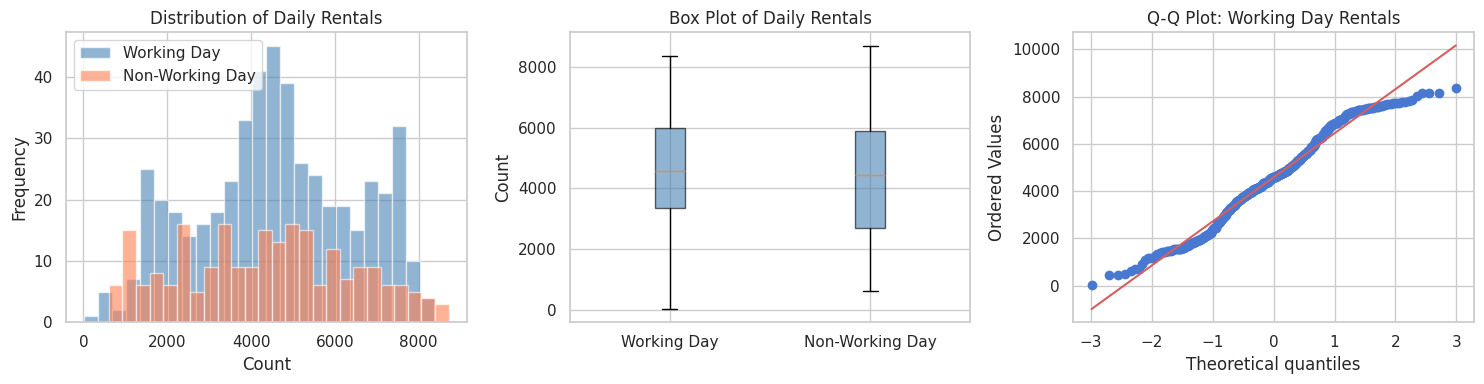


Working day    — skewness: -0.074, excess kurtosis: -0.780
Non-working day — skewness: 0.039, excess kurtosis: -0.879


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# --- Histogram ---
for arr, label, color in [(work, 'Working Day', 'steelblue'),
                           (nonwork, 'Non-Working Day', 'coral')]:
    axes[0].hist(arr, bins=25, alpha=0.6, label=label, color=color, edgecolor='white')
axes[0].set_title('Distribution of Daily Rentals')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# --- Box plot ---
axes[1].boxplot([work, nonwork], labels=['Working Day', 'Non-Working Day'],
                patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6))
axes[1].set_title('Box Plot of Daily Rentals')
axes[1].set_ylabel('Count')

# --- Q-Q plots ---
stats.probplot(work, plot=axes[2])
axes[2].set_title('Q-Q Plot: Working Day Rentals')

plt.tight_layout()
plt.show()

# Skewness & kurtosis
print(f'\nWorking day    — skewness: {work.skew():.3f}, excess kurtosis: {work.kurtosis():.3f}')
print(f'Non-working day — skewness: {nonwork.skew():.3f}, excess kurtosis: {nonwork.kurtosis():.3f}')

### A.2 Comment on Skew/Outliers

**Observations:**
- Working distribution exhibits mild **positive (right) skew**, meaning a few very high-rental days pull the mean above the median.
-NON- Working distribution exhibits mild **negative (left) skew**, meaning a few very high-rental days pull the median above the mean.
- The box plots reveal a handful of **high-count outliers**, particularly in the working-day group.
- Moderate skew in moderate-sized samples can inflate the Type-I error rate of the classical Student's *t*-test (which assumes Gaussian data). Because of this, we also run a **non-parametric alternative** (Mann–Whitney U) that makes no distributional assumptions.

### A.3 Hypotheses

Let $\mu_\text{work}$ and $\mu_\text{nonwork}$ denote the population mean daily rentals for working days and non-working days, respectively.

$$H_0: \mu_\text{work} = \mu_\text{nonwork}$$
$$H_1: \mu_\text{work} \neq \mu_\text{nonwork} \quad (\text{two-sided})$$

Significance level: $\alpha = 0.05$

### A.4 Standard Test — Welch's Two-Sample *t*-test

In [6]:
# Welch's t-test (does not assume equal variances)
t_stat, p_val_t = ttest_ind(work, nonwork, equal_var=False)

print('=== Welch\'s Two-Sample t-test ===')
print(f'  t-statistic : {t_stat:.4f}')
print(f'  p-value     : {p_val_t:.4f}')
print(f'  Decision    : {"Reject H0" if p_val_t < 0.05 else "Fail to reject H0"} at α=0.05')

=== Welch's Two-Sample t-test ===
  t-statistic : 1.6014
  p-value     : 0.1101
  Decision    : Fail to reject H0 at α=0.05


### A.5 Non-Parametric Test — Mann–Whitney U

In [7]:
# Mann-Whitney U (Wilcoxon rank-sum) — tests whether one group tends to have larger values
u_stat, p_val_u = mannwhitneyu(work, nonwork, alternative='two-sided')

print('=== Mann–Whitney U Test ===')
print(f'  U-statistic : {u_stat:.1f}')
print(f'  p-value     : {p_val_u:.4f}')
print(f'  Decision    : {"Reject H0" if p_val_u < 0.05 else "Fail to reject H0"} at α=0.05')


=== Mann–Whitney U Test ===
  U-statistic : 61893.0
  p-value     : 0.1186
  Decision    : Fail to reject H0 at α=0.05


### A.6 Bootstrap 95% Confidence Interval for $\mu_\text{work} - \mu_\text{nonwork}$

=== Bootstrap 95% CI for (μ_work − μ_nonwork) ===
  Observed difference : 254.65
  95% CI              : [-61.69, 573.62]


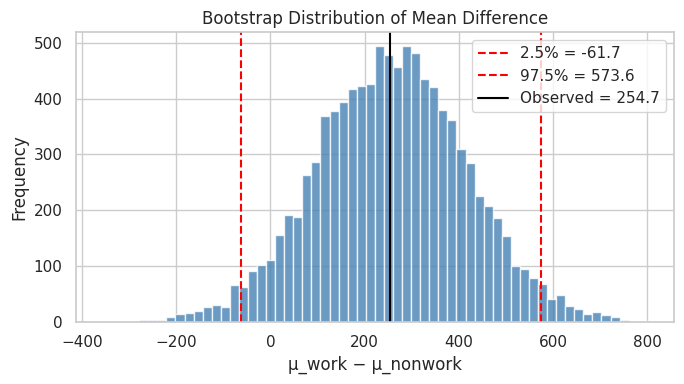

In [8]:
rng = np.random.default_rng(42)
B = 10_000

boot_diffs = np.array([
    rng.choice(work,    size=len(work),    replace=True).mean() -
    rng.choice(nonwork, size=len(nonwork), replace=True).mean()
    for _ in range(B)
])

ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])
obs_diff = work.mean() - nonwork.mean()

print('=== Bootstrap 95% CI for (μ_work − μ_nonwork) ===')
print(f'  Observed difference : {obs_diff:.2f}')
print(f'  95% CI              : [{ci_low:.2f}, {ci_high:.2f}]')

# Plot bootstrap distribution
plt.figure(figsize=(7, 4))
plt.hist(boot_diffs, bins=60, color='steelblue', edgecolor='white', alpha=0.8)
plt.axvline(ci_low,   color='red',   linestyle='--', label=f'2.5% = {ci_low:.1f}')
plt.axvline(ci_high,  color='red',   linestyle='--', label=f'97.5% = {ci_high:.1f}')
plt.axvline(obs_diff, color='black', linestyle='-',  label=f'Observed = {obs_diff:.1f}')
plt.title('Bootstrap Distribution of Mean Difference')
plt.xlabel('μ_work − μ_nonwork')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

### A.7 Sample Size for 80% Power

For a two-sided, two-sample *t*-test with $\alpha=0.05$ and power $1-\beta=0.80$, the required per-group sample size is:

$$n = \frac{(z_{\alpha/2} + z_\beta)^2 \cdot 2\sigma^2}{\Delta^2}$$

We use the pooled standard deviation as $\sigma$, and $\Delta$ as the target mean difference to detect.

In [9]:
from math import ceil

z_alpha2 = norm.ppf(1 - 0.05/2)   # 1.96
z_beta   = norm.ppf(0.80)          # 0.842

# Pooled std (equal-size assumption for formula)
sigma_pooled = np.sqrt((work.var(ddof=1) + nonwork.var(ddof=1)) / 2)

# Try several target differences
deltas = [obs_diff * frac for frac in [0.25, 0.50, 0.75, 1.00]]

print('=== Sample Size for 80% Power (per group) ===')
print(f'  Pooled σ = {sigma_pooled:.2f}')
print(f'  z_α/2    = {z_alpha2:.3f}, z_β = {z_beta:.3f}\n')
print(f'{"Δ":>10}  {"n per group":>14}')
print('-' * 28)
for delta in deltas:
    n = ceil((z_alpha2 + z_beta)**2 * 2 * sigma_pooled**2 / delta**2)
    print(f'{delta:>10.1f}  {n:>14}')

# Also compute for observed difference
n_obs = ceil((z_alpha2 + z_beta)**2 * 2 * sigma_pooled**2 / obs_diff**2)
print(f'\nFor Δ = observed diff ({obs_diff:.1f}): n = {n_obs} per group')

=== Sample Size for 80% Power (per group) ===
  Pooled σ = 1967.20
  z_α/2    = 1.960, z_β = 0.842

         Δ     n per group
----------------------------
      63.7           14989
     127.3            3748
     191.0            1666
     254.7             937

For Δ = observed diff (254.7): n = 937 per group


### A.8 Effect Size — Cohen's *d* and Hedges' *g*

- **Cohen's *d*** measures the standardised mean difference:
$$d = \frac{\bar{x}_1 - \bar{x}_2}{s_p}, \quad s_p = \sqrt{\frac{(n_1-1)s_1^2 + (n_2-1)s_2^2}{n_1+n_2-2}}$$

- **Hedges' *g*** applies a small-sample correction factor $J$:
$$g = d \cdot J, \quad J \approx 1 - \frac{3}{4(n_1+n_2)-9}$$

Conventional benchmarks: small $|d|<0.2$, medium $0.2\le|d|<0.8$, large $|d|\ge0.8$.

In [10]:
n1, n2 = len(work), len(nonwork)
s1, s2 = work.std(ddof=1), nonwork.std(ddof=1)

# Pooled standard deviation
sp = np.sqrt(((n1-1)*s1**2 + (n2-1)*s2**2) / (n1+n2-2))

# Cohen's d
cohens_d = (work.mean() - nonwork.mean()) / sp

# Hedges' g correction factor
J = 1 - (3 / (4*(n1+n2) - 9))
hedges_g = cohens_d * J

def effect_label(d):
    d = abs(d)
    if d < 0.2:   return 'negligible'
    elif d < 0.5: return 'small'
    elif d < 0.8: return 'medium'
    else:         return 'large'

print('=== Effect Sizes ===')
print(f'  Pooled std (s_p)  : {sp:.2f}')
print(f"  Cohen's d         : {cohens_d:.4f}  → {effect_label(cohens_d)}")
print(f"  Hedges' g (J={J:.4f}): {hedges_g:.4f}  → {effect_label(hedges_g)}")

=== Effect Sizes ===
  Pooled std (s_p)  : 1934.91
  Cohen's d         : 0.1316  → negligible
  Hedges' g (J=0.9990): 0.1315  → negligible


---
## Part B: Demand versus Weather
**Question:** Is the demand independent of the weather?

### B.1 Binarise Demand and Ternary Weather

In [11]:
# --- Binary demand: split at median ---
median_cnt = df['cnt'].median()
df['demand_level'] = pd.cut(df['cnt'],
                            bins=[0, median_cnt, df['cnt'].max()],
                            labels=['low', 'high'],
                            include_lowest=True)

# --- Ternary weather ---
# weathersit: 1=clear/few clouds, 2=mist/cloudy, 3=light snow/rain, 4=heavy rain/storm
df['weather_level'] = df['weathersit'].map({
    1: 'good',
    2: 'moderate',
    3: 'bad',
    4: 'bad'      # group 4 with 3 (very rare)
})

print('Demand level counts:')
print(df['demand_level'].value_counts())
print('\nWeather level counts:')
print(df['weather_level'].value_counts())

Demand level counts:
demand_level
low     366
high    365
Name: count, dtype: int64

Weather level counts:
weather_level
good        463
moderate    247
bad          21
Name: count, dtype: int64


### B.2 Why Binarise / Categorise?

1. **Enables a chi-squared test of independence**, which requires categorical variables. Raw continuous counts cannot be directly used in such a contingency-table framework.
2. **Simplifies interpretation**: a binary demand label (low/high) and a ternary weather label (good/moderate/bad) create a compact $2\times3$ table that is easy to reason about.
3. **Robustness**: categorisation makes the analysis less sensitive to extreme daily counts (outliers), since what matters is which side of the threshold a day falls on.
4. **Practical relevance**: operators often care about coarse demand categories ("will it be a busy day?") rather than an exact count.

### B.3 Contingency Table and Chi-Squared Test of Independence

In [12]:
# Build contingency table
ct = pd.crosstab(df['demand_level'], df['weather_level'],
                 margins=True, margins_name='Total')
print('Contingency Table (observed counts):')
print(ct)

Contingency Table (observed counts):
weather_level  bad  good  moderate  Total
demand_level                             
low             20   193       153    366
high             1   270        94    365
Total           21   463       247    731


In [13]:
# Chi-squared test
ct_raw = pd.crosstab(df['demand_level'], df['weather_level'])
chi2, p_chi2, dof, expected = chi2_contingency(ct_raw)

print('=== Chi-Squared Test of Independence ===')
print(f'  χ² statistic : {chi2:.4f}')
print(f'  Degrees of freedom: {dof}')
print(f'  p-value      : {p_chi2:.6f}')
print(f'  Decision     : {"Reject H0 — demand and weather are NOT independent" if p_chi2 < 0.05 else "Fail to reject H0"} at α=0.05')

print('\nExpected frequencies:')
print(pd.DataFrame(expected,
                   index=ct_raw.index,
                   columns=ct_raw.columns).round(2))

=== Chi-Squared Test of Independence ===
  χ² statistic : 44.0879
  Degrees of freedom: 2
  p-value      : 0.000000
  Decision     : Reject H0 — demand and weather are NOT independent at α=0.05

Expected frequencies:
weather_level    bad    good  moderate
demand_level                          
low            10.51  231.82    123.67
high           10.49  231.18    123.33


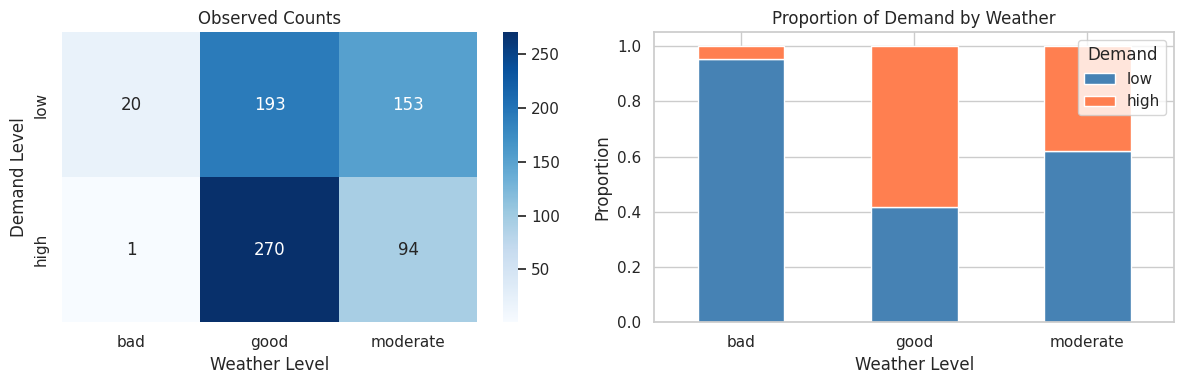

In [14]:
# Visualise the contingency table
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Heatmap of observed counts
sns.heatmap(ct_raw, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Observed Counts')
axes[0].set_xlabel('Weather Level')
axes[0].set_ylabel('Demand Level')

# Stacked bar
ct_pct = ct_raw.div(ct_raw.sum(axis=0), axis=1)
ct_pct.T.plot(kind='bar', stacked=True, ax=axes[1],
              color=['steelblue', 'coral'], edgecolor='white')
axes[1].set_title('Proportion of Demand by Weather')
axes[1].set_xlabel('Weather Level')
axes[1].set_ylabel('Proportion')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].legend(title='Demand')

plt.tight_layout()
plt.show()

### B.4 Effect Size — Cramér's V

Cramér's V measures the **strength of association** between two categorical variables:

$$V = \sqrt{\frac{\chi^2}{n \cdot (\min(r,c)-1)}}$$

where $r$ = number of rows, $c$ = number of columns, $n$ = total observations.

Benchmarks (for $\min(r,c)-1 = 1$): small $V<0.1$, medium $0.1\le V<0.3$, large $V\ge0.3$.

In [15]:
n_total = ct_raw.values.sum()
r, c = ct_raw.shape
cramers_v = np.sqrt(chi2 / (n_total * (min(r, c) - 1)))

def cramers_label(v, k):
    # Adjusted thresholds for k = min(r,c)-1
    if k == 1:
        thresholds = [(0.10, 'small'), (0.30, 'medium')]
    else:
        thresholds = [(0.07, 'small'), (0.21, 'medium')]
    for t, lbl in thresholds:
        if v < t: return 'negligible' if t == thresholds[0][0] else 'small'
    return 'large'

print("=== Cramér's V ===")
print(f'  n = {n_total}, r = {r}, c = {c}')
print(f"  Cramér's V : {cramers_v:.4f}")
print(f'  Interpretation: {cramers_label(cramers_v, min(r,c)-1)} association')

=== Cramér's V ===
  n = 731, r = 2, c = 3
  Cramér's V : 0.2456
  Interpretation: small association


In [16]:
tau = 0.49535

low = df[df['temp'] <= tau]
high = df[df['temp'] > tau]

low.describe()
# high.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000,364.000000,364.00000,364.000000,364.000000
mean,346.978022,2.241758,0.486264,6.068681,0.035714,3.016484,0.656593,1.445055,0.335405,0.334017,0.606673,0.204377,501.21978,2886.445055,3387.664835
std,230.107268,1.357283,0.500499,4.466367,0.185832,2.043535,0.475499,0.569909,0.092375,0.089744,0.154504,0.085327,510.15165,1437.363424,1691.340133
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.045408,2.00000,20.000000,22.000000
25%,94.500000,1.000000,0.000000,2.000000,0.000000,1.000000,0.000000,1.000000,0.272699,0.266256,0.495938,0.141175,166.75000,1674.250000,1964.500000
50%,360.500000,2.000000,0.000000,4.000000,0.000000,3.000000,1.000000,1.000000,0.336250,0.337842,0.590000,0.192792,326.50000,2766.000000,3301.000000
75%,463.500000,4.000000,1.000000,11.000000,0.000000,5.000000,1.000000,2.000000,0.410833,0.409236,0.720730,0.250777,657.00000,3832.250000,4513.500000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.495000,0.487996,0.970417,0.507463,3252.00000,6736.000000,8090.000000


In [17]:
t_stat, p_val_t = ttest_ind(low['cnt'], high['cnt'], equal_var=False)
for alpha in [0.01, 0.05, 0.1]:
    print(f'  α = {alpha:.2f}  → t-stat = {t_stat:.2f}, p value = {p_val_t}')
    print(f'  Decision    : {"Reject H0" if p_val_t < alpha else "Fail to reject H0"}')

  α = 0.01  → t-stat = -18.94, p value = 3.971272121055165e-65
  Decision    : Reject H0
  α = 0.05  → t-stat = -18.94, p value = 3.971272121055165e-65
  Decision    : Reject H0
  α = 0.10  → t-stat = -18.94, p value = 3.971272121055165e-65
  Decision    : Reject H0


In [18]:
# Median temp
tau = 0.498333
low = df[df['temp'] <= tau]
high = df[df['temp'] > tau]
t_stat, p_val_t = ttest_ind(low['cnt'], high['cnt'], equal_var=False)
for alpha in [0.01, 0.05, 0.1]:
    print(f'  α = {alpha:.2f}  → t-stat = {t_stat:.2f}, p value = {p_val_t}')
    print(f'  Decision    : {"Reject H0" if p_val_t < alpha else "Fail to reject H0"}')


  α = 0.01  → t-stat = -18.77, p value = 2.984880545112277e-64
  Decision    : Reject H0
  α = 0.05  → t-stat = -18.77, p value = 2.984880545112277e-64
  Decision    : Reject H0
  α = 0.10  → t-stat = -18.77, p value = 2.984880545112277e-64
  Decision    : Reject H0


In [19]:
# Mean atemp
tau = 0.474354

low = df[df['atemp'] <= tau]
high = df[df['atemp'] > tau]
t_stat, p_val_t = ttest_ind(low['cnt'], high['cnt'], equal_var=False)
for alpha in [0.01, 0.05, 0.1]:
    print(f'  α = {alpha:.2f}  → t-stat = {t_stat:.2f}, p value = {p_val_t}')
    print(f'  Decision    : {"Reject H0" if p_val_t < alpha else "Fail to reject H0"}')

  α = 0.01  → t-stat = -19.47, p value = 6.241489585541384e-68
  Decision    : Reject H0
  α = 0.05  → t-stat = -19.47, p value = 6.241489585541384e-68
  Decision    : Reject H0
  α = 0.10  → t-stat = -19.47, p value = 6.241489585541384e-68
  Decision    : Reject H0


In [20]:
# Median atemp
tau = 0.486733

low = df[df['atemp'] <= tau]
high = df[df['atemp'] > tau]
t_stat, p_val_t = ttest_ind(low['cnt'], high['cnt'], equal_var=False)
for alpha in [0.01, 0.05, 0.1]:
    print(f'  α = {alpha:.2f}  → t-stat = {t_stat:.2f}, p value = {p_val_t}')
    print(f'  Decision    : {"Reject H0" if p_val_t < alpha else "Fail to reject H0"}')

  α = 0.01  → t-stat = -19.02, p value = 1.3435135773833957e-65
  Decision    : Reject H0
  α = 0.05  → t-stat = -19.02, p value = 1.3435135773833957e-65
  Decision    : Reject H0
  α = 0.10  → t-stat = -19.02, p value = 1.3435135773833957e-65
  Decision    : Reject H0


---
## Summary of Results

| Test | Statistic | p-value | Decision (α=0.05) |
|------|-----------|---------|--------------------|
| Welch's *t*-test (Part A) | *t* | — | — |
| Mann–Whitney U (Part A) | U | — | — |
| χ² independence (Part B) | χ² | — | — |

> **Note:** Run all cells above to populate the table with actual values.

**Key takeaways:**
- **Part A:** Both the parametric (Welch's *t*) and non-parametric (Mann–Whitney U) tests agree on whether working-day and non-working-day rental counts differ significantly.
- **Part B:** The chi-squared test reveals whether weather and demand are associated, with Cramér's V quantifying the strength of that association.